# Unemployment in India
## The 2020 lockdown and labour-market rebound
**Task 2 · Unemployment Analysis with Python**

### 01 · Project introduction
Monthly labour-market estimates make it possible to track the spring 2020 disruption and compare the rebound across regions and areas. Unemployment is the share of the labour force without work. Participation and estimated employment help interpret how the unemployment rate changed.

### 02 · Research objectives
1. Describe unemployment, employment and participation.
2. Measure changes around the nationwide lockdown and compare matched regions.
3. Examine regional variation and urban/rural differences.
4. Investigate recurring calendar patterns within the available period.
5. Translate observed changes into policy questions that can be tested.

### 03 · Dataset overview
The [official Kaggle release](https://www.kaggle.com/datasets/gokulrajkmv/unemployment-in-india) contains a region-by-area file and a region-wide file. Their observation keys and weights differ. The analysis keeps the two series separate. The project data dictionary lists the original labels, cleaned names and units.

### 04 · Library imports
The notebook reuses the project's Python modules. It resolves paths when launched from either the project root or the notebook folder.

In [1]:
from pathlib import Path
import sys
from io import BytesIO

root = Path.cwd()
if not (root / "main.py").exists():
    root = root.parent
sys.path.insert(0, str(root))

import pandas as pd
from IPython.display import Image, Markdown, display
from PIL import Image as PILImage

from main import analyze, prepare
from src.report_generator import findings
from src.visualization import charts

pd.options.display.max_columns = 12
pd.options.display.float_format = "{:,.2f}".format

### 05 · Data loading
The loader validates the original files against the recorded byte counts and SHA-256 hashes. It obtains the public ZIP if the originals are missing.

In [2]:
from src.data_loader import load_raw
raw, metadata = load_raw(root / "data" / "raw")
display(pd.DataFrame.from_dict(metadata["files"], orient="index").drop(columns="sha256"))
print(metadata["acquisition"], metadata.get("downloaded_at_utc", ""))

,bytes,rows,columns
Unemployment in India.csv,47043,768,7
Unemployment_Rate_upto_11_2020.csv,18274,267,9


Official Kaggle public dataset API (unauthenticated ZIP) 2026-11-09T15:32:41.277456+00:00


### 06 · Initial inspection
Inspect source headers, first and last rows, types, numerical summaries and categorical levels. The blank tail in the area CSV remains visible here. Cleaned date ranges and coverage follow in the quality audit.

In [3]:
for grain, frame in raw.items():
    print(grain, frame.shape, list(frame.columns))
    display(pd.concat([frame.head(2), frame.tail(2)]))
    display(frame.dtypes.astype(str).rename("dtype").to_frame().T)
    display(frame.select_dtypes("number").describe().T)
    for column in [" Frequency", "Area", "Region.1"]:
        if column in frame:
            print(column.strip(), frame[column].dropna().astype(str).str.strip().value_counts().to_dict())
    print("Regions", sorted(frame["Region"].dropna().unique()))

area (768, 7) ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,"11,999,139.00",43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,"11,755,881.00",42.05,Rural
766,NaN,NaN,NaN,NaN,NaN,NaN,NaN
767,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
dtype,object,object,object,float64,float64,float64,object


,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),740.00,11.79,10.72,0.00,4.66,8.35,15.89,76.74
Estimated Employed,740.00,"7,204,460.03","8,087,988.43","49,420.00","1,190,404.50","4,744,178.50","11,275,489.50","45,777,509.00"
Estimated Labour Participation Rate (%),740.00,42.63,8.11,13.33,38.06,41.16,45.51,72.57


Frequency {'Monthly': 740}
Area {'Urban': 381, 'Rural': 359}
Regions ['Andhra Pradesh', 'Assam', 'Bihar', 'Chandigarh', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']
regional (267, 9) ['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Region.1', 'longitude', 'latitude']


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
0,Andhra Pradesh,31-01-2020,M,5.48,16635535,41.02,South,15.91,79.74
1,Andhra Pradesh,29-02-2020,M,5.83,16545652,40.90,South,15.91,79.74
265,West Bengal,30-09-2020,M,9.35,35707239,47.73,East,22.99,87.86
266,West Bengal,31-10-2020,M,9.98,33962549,45.63,East,22.99,87.86


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Region.1,longitude,latitude
dtype,object,object,object,float64,int64,float64,object,float64,float64


,count,mean,std,min,25%,50%,75%,max
Estimated Unemployment Rate (%),267.00,12.24,10.80,0.50,4.84,9.65,16.75,75.85
Estimated Employed,267.00,"13,962,105.72","13,366,318.36","117,542.00","2,838,930.50","9,732,417.00","21,878,686.00","59,433,759.00"
Estimated Labour Participation Rate (%),267.00,41.68,7.85,16.77,37.27,40.39,44.05,69.69
longitude,267.00,22.83,6.27,10.85,18.11,23.61,27.28,33.78
latitude,267.00,80.53,5.83,71.19,76.09,79.02,85.28,92.94


Frequency {'M': 267}
Region.1 {'North': 79, 'South': 60, 'West': 50, 'East': 40, 'Northeast': 38}
Regions ['Andhra Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Goa', 'Gujarat', 'Haryana', 'Himachal Pradesh', 'Jammu & Kashmir', 'Jharkhand', 'Karnataka', 'Kerala', 'Madhya Pradesh', 'Maharashtra', 'Meghalaya', 'Odisha', 'Puducherry', 'Punjab', 'Rajasthan', 'Sikkim', 'Tamil Nadu', 'Telangana', 'Tripura', 'Uttar Pradesh', 'Uttarakhand', 'West Bengal']


### 07 · Data cleaning
The pipeline trims labels, normalizes frequency, parses dates day-first and validates labour metrics. Fully empty records are removed and IQR flags are retained. The two reversed geographic headers are corrected using the coordinate ranges. No values are imputed.

In [4]:
raw, clean, quality, inventory, metadata = prepare(root / "data" / "raw")
display(inventory)
for grain, frame in clean.items():
    print(grain, frame.shape)
    display(frame.head(2))

,source,filename,raw_rows,raw_columns,cleaned_rows,regions,first_month,last_month
0,area,Unemployment in India.csv,768,7,740,28,2019-05-01,2020-06-01
1,regional,Unemployment_Rate_upto_11_2020.csv,267,9,267,27,2020-01-01,2020-10-01


area (740, 9)


,region,date,frequency,unemployment_rate,employed,participation_rate,area,month,iqr_outlier
0,Andhra Pradesh,2019-05-31,Monthly,3.65,"11,999,139.00",43.24,Rural,2019-05-01,False
1,Andhra Pradesh,2019-05-31,Monthly,6.09,"4,788,661.00",37.45,Urban,2019-05-01,False


regional (267, 11)


,region,date,frequency,unemployment_rate,employed,participation_rate,macro_region,latitude,longitude,month,iqr_outlier
0,Andhra Pradesh,2020-01-31,Monthly,5.48,16635535,41.02,South,15.91,79.74,2020-01-01,False
1,Andhra Pradesh,2020-02-29,Monthly,5.83,16545652,40.90,South,15.91,79.74,2020-02-01,False


### 08 · Data quality assessment
Review missing values before and after excluding fully blank rows. A separate coverage audit identifies region-month keys that are absent entirely. Cross-source overlap is a diagnostic because urban and rural unemployment require labour-force weights to aggregate.

In [5]:
tables = analyze(raw, clean, quality, inventory)
summary = findings(tables)
display(quality.query("count > 0"))
display(tables["missing_regional_months"])
print("Absent region-month-area cells", len(tables["missing_region_month_areas"]))
print("Nonblank rows with missing measurements by source",
      {k: len(tables[f"nonblank_missing_{k}"]) for k in clean})
display(Markdown(summary["overlap"]))

,source,check,field,count,decision,pct_of_raw_rows
0,area,input_rows,all,768,Count includes empty CSV records,NaN
1,area,blank_rows_removed,all,28,All fields empty,NaN
3,area,raw_missing,region,28,Includes blank records,3.65
4,area,raw_missing,date,28,Includes blank records,3.65
5,area,raw_missing,frequency,28,Includes blank records,3.65
6,area,raw_missing,unemployment_rate,28,Includes blank records,3.65
7,area,raw_missing,employed,28,Includes blank records,3.65
8,area,raw_missing,participation_rate,28,Includes blank records,3.65
9,area,raw_missing,area,28,Includes blank records,3.65
22,area,iqr_flags_retained,unemployment_rate,35,1.5 IQR fences -12.19 to 32.73; retained,NaN


,region,month
0,Jammu & Kashmir,2020-04-01
1,Sikkim,2020-01-01
2,Sikkim,2020-02-01


Absent region-month-area cells 44
Nonblank rows with missing measurements by source {'area': 0, 'regional': 0}


The files overlap in 158 region-month keys, with both areas present in 148. In 144 of those, the regional rate differs from the simple area mean by more than 0.011 pp. Area percentages require labour-force weights to aggregate. The two files serve separate analytical roles.

### 09 · Exploratory data analysis
Compare distributions across the two native units. Means of observed units are descriptive. The recorded peaks are bounded and occur during the observed disruption.

In [6]:
display(tables["descriptive_statistics"])
display(tables["largest_observations"][["source", "region", "month", "unemployment_rate"]].head(12))
display(Markdown(summary["distribution"]))

figure_paths = charts(tables, clean["area"], clean["regional"], root / "outputs" / "figures")

def show(key):
    with PILImage.open(figure_paths[key]) as picture:
        picture.thumbnail((1260, 875))
        buffer = BytesIO()
        picture.save(buffer, format="PNG")
    display(Image(data=buffer.getvalue()))

,metric,count,mean,std,min,25%,50%,75%,max,iqr,source
0,unemployment_rate,740.00,11.79,10.72,0.00,4.66,8.35,15.89,76.74,11.23,area
1,employed,740.00,"7,204,460.03","8,087,988.43","49,420.00","1,190,404.50","4,744,178.50","11,275,489.50","45,777,509.00","10,085,085.00",area
2,participation_rate,740.00,42.63,8.11,13.33,38.06,41.16,45.51,72.57,7.44,area
3,unemployment_rate,267.00,12.24,10.80,0.50,4.84,9.65,16.75,75.85,11.91,regional
4,employed,267.00,"13,962,105.72","13,366,318.36","117,542.00","2,838,930.50","9,732,417.00","21,878,686.00","59,433,759.00","19,039,755.50",regional
5,participation_rate,267.00,41.68,7.85,16.77,37.27,40.39,44.05,69.69,6.79,regional


,source,region,month,unemployment_rate
0,area,Puducherry,2020-04-01,76.74
1,area,Puducherry,2020-05-01,75.00
2,area,Puducherry,2020-04-01,74.51
3,area,Jharkhand,2020-05-01,70.17
4,area,Jharkhand,2020-04-01,61.48
5,area,Bihar,2020-04-01,58.77
6,area,Jharkhand,2020-05-01,55.10
7,area,Tamil Nadu,2020-04-01,53.19
8,area,Himachal Pradesh,2020-05-01,50.00
9,area,Bihar,2020-05-01,47.26


Across all 267 region-month estimates, unemployment averaged 12.24% with a median of 9.65% and SD of 10.80 pp. Values ranged from 0.50% to 75.85%, with the middle half between 4.84% and 16.75% (IQR 11.91 pp).

### 10 · Unemployment trend analysis
The historical trend fixes both area observations across the same regions in every month. The three-month trailing average smooths the jump and therefore remains elevated in June.

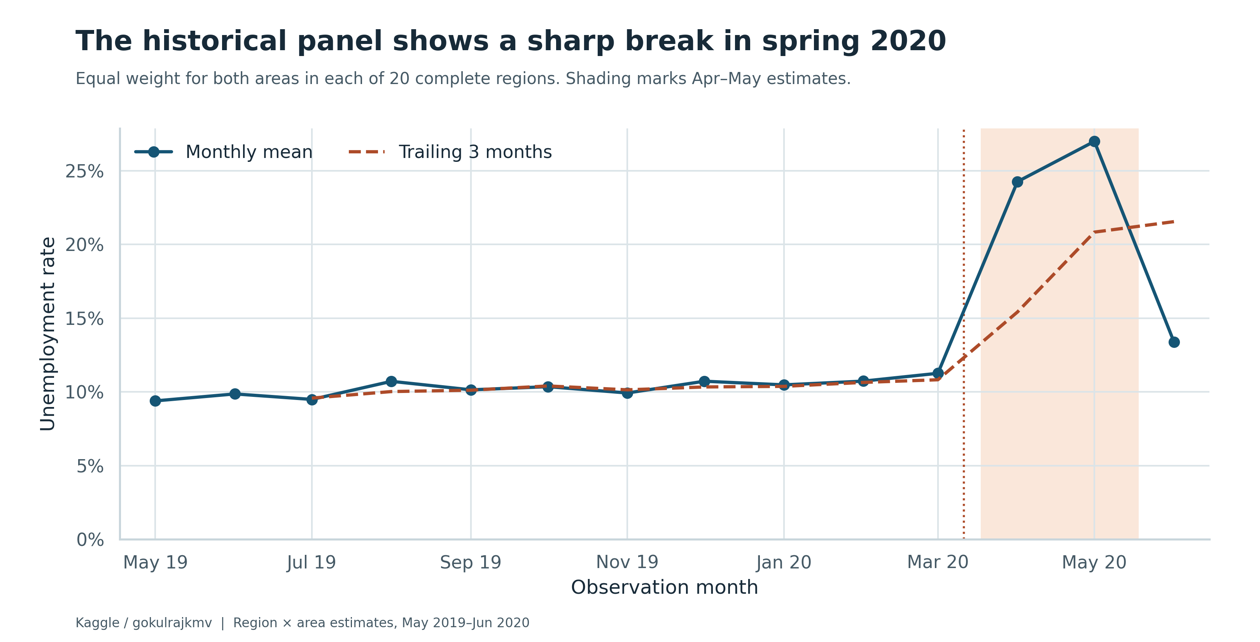

,month,unemployment_rate,rolling_3m_rate,change_pp
0,2019-05-01,9.39,NaN,NaN
1,2019-06-01,9.86,NaN,0.47
2,2019-07-01,9.48,9.58,-0.37
3,2019-08-01,10.71,10.02,1.23
4,2019-09-01,10.13,10.11,-0.58
5,2019-10-01,10.35,10.40,0.21
6,2019-11-01,9.92,10.13,-0.43
7,2019-12-01,10.72,10.33,0.80
8,2020-01-01,10.47,10.37,-0.25
9,2020-02-01,10.73,10.64,0.25


In [7]:
show("02_historical_trend")
display(tables["historical_monthly"][["month", "unemployment_rate", "rolling_3m_rate", "change_pp"]])

### 11 · Regional analysis
Rankings summarize available months. Lockdown changes compare periods for the same region in a complete monthly panel. Gray heatmap cells indicate missing observations.

Haryana had the highest observed-month mean (27.48%), Meghalaya the lowest (3.87%), and Puducherry the largest within-region SD (26.59 pp). The largest paired increases were Puducherry (+65.85 pp), Jharkhand (+41.93 pp), Tamil Nadu (+39.66 pp). The highest individual estimates were 75.85% in Puducherry (April 2020, region-wide) and 76.74% in Puducherry (April 2020, urban).

,region,n,mean,median,sd,minimum,maximum
0,Haryana,10,27.48,26.23,6.82,19.68,43.22
1,Tripura,10,25.05,24.82,8.66,11.57,41.23
2,Jharkhand,10,19.54,11.21,18.34,7.63,59.23
3,Bihar,10,19.47,13.11,14.35,9.82,46.64
4,Delhi,10,18.41,16.86,9.48,6.27,42.27


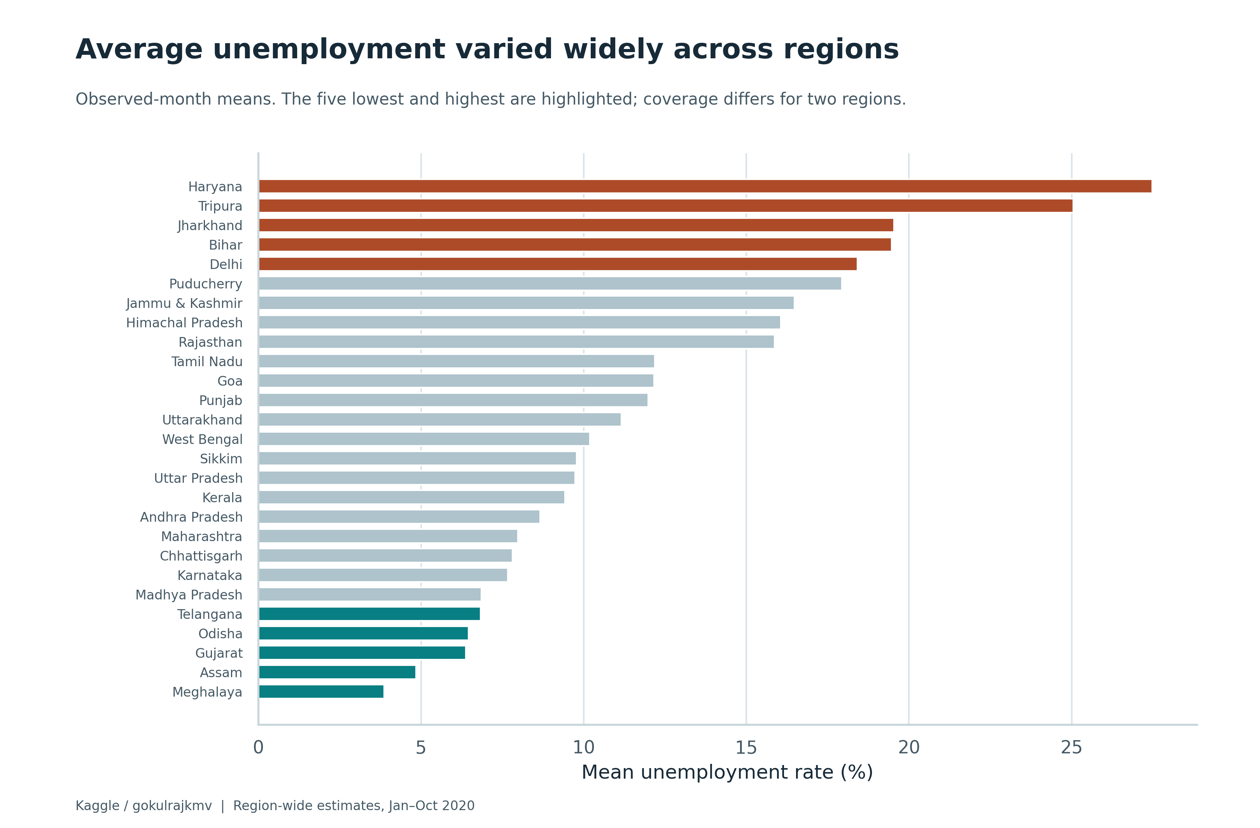

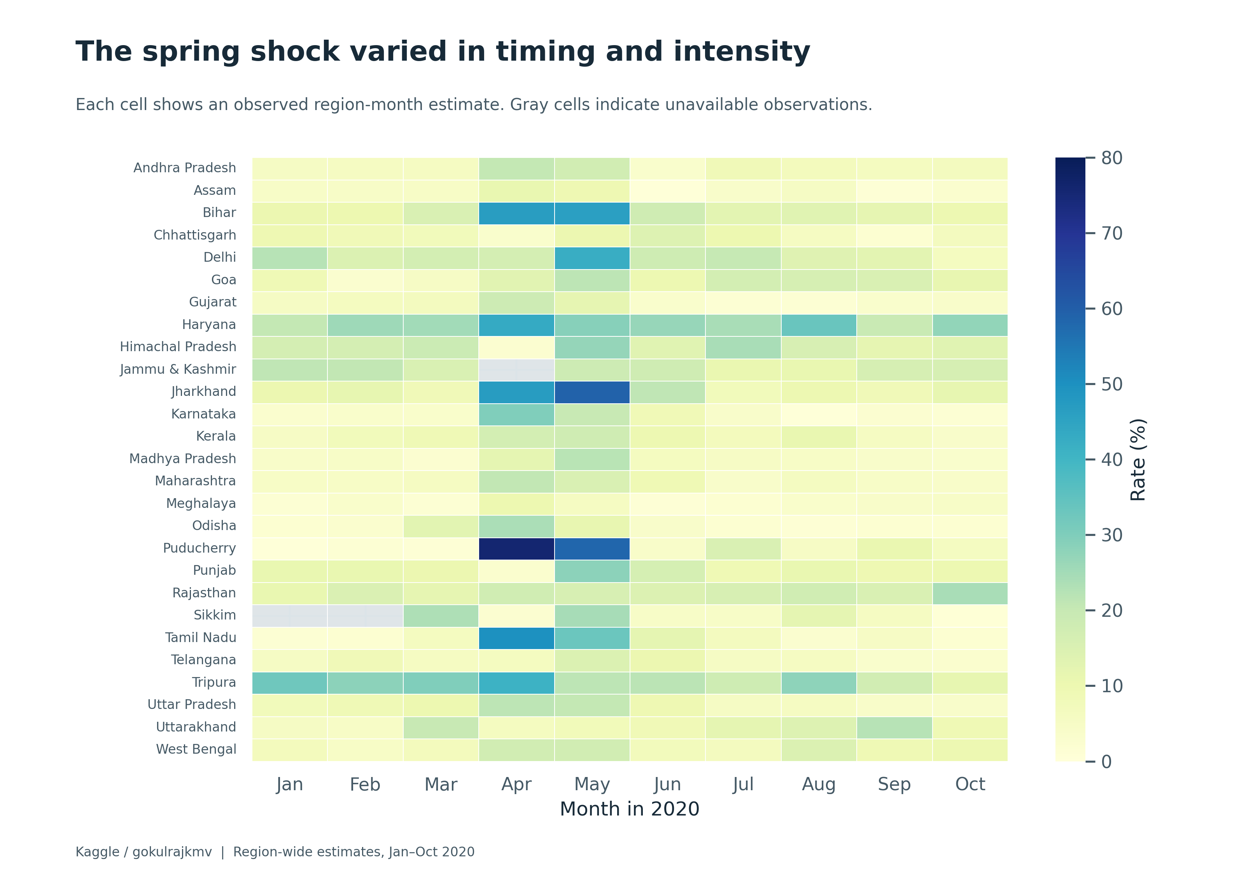

In [8]:
display(Markdown(summary["region"]))
display(tables["regional_summary"].head())
show("04_regional_ranking")
show("08_regional_heatmap")

### 12 · Urban versus rural analysis
The comparison uses the recorded Area field and a fixed set of regions with complete rural and urban observations from January to June. Urban and rural employment counts describe different populations.

,area,period,unemployment_rate,unemployment_change_pp,participation_change_pp,employment_relative_pct
0,Rural,Baseline,9.00,0.00,0.00,0.00
1,Rural,Transition,10.45,1.45,-1.22,-3.68
2,Rural,Shock,23.31,14.31,-7.52,-27.63
3,Rural,Reopening,12.94,3.94,-2.35,-7.46
4,Rural,Pandemic,19.86,10.85,-5.79,-20.91
5,Urban,Baseline,12.20,0.00,0.00,0.00
6,Urban,Transition,12.06,-0.14,-1.28,-1.92
7,Urban,Shock,27.92,15.72,-9.29,-32.72
8,Urban,Reopening,13.83,1.64,-4.08,-9.26
9,Urban,Pandemic,23.22,11.03,-7.55,-24.90


Across 20 regions with both areas, urban unemployment rose from 12.20% to 27.92% (+15.72 pp); rural unemployment rose from 9.00% to 23.31% (+14.31 pp). The estimated urban-minus-rural change was +1.41 pp (95% region bootstrap interval -2.42 to 5.14 pp). The interval spans zero, leaving the difference uncertain.

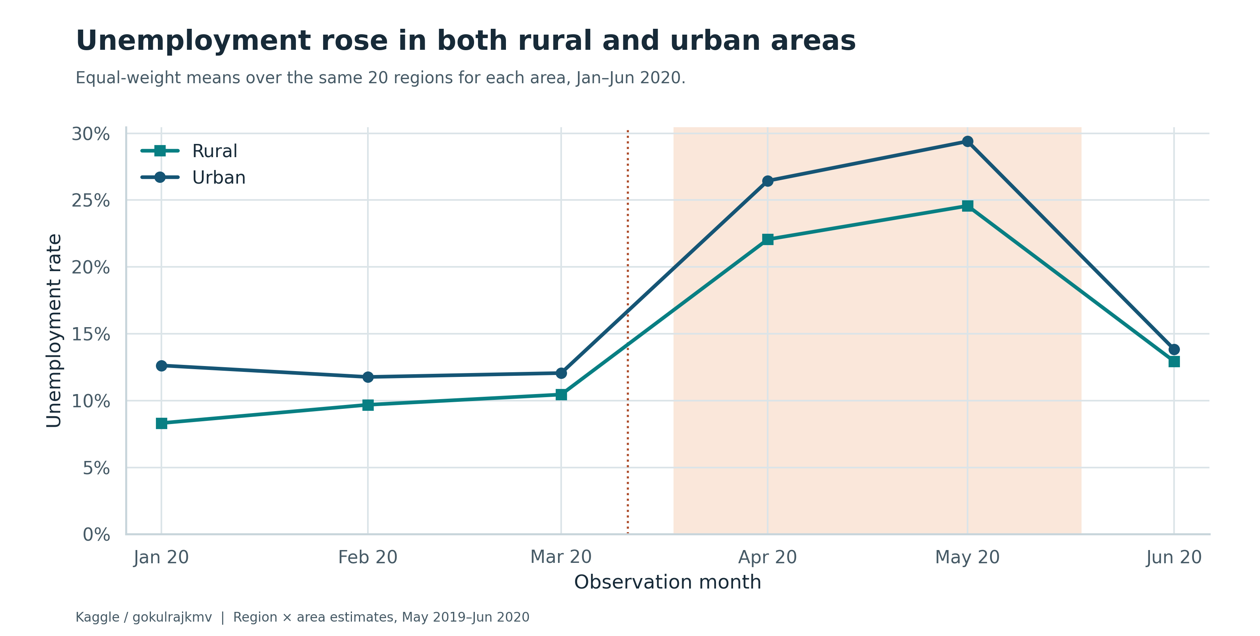

In [9]:
fields = ["period", "unemployment_rate", "unemployment_change_pp",
          "participation_change_pp", "employment_relative_pct"]
display(tables["covid_by_area"][["area", *fields]])
display(Markdown(summary["area"]))
show("06_urban_rural")

### 13 · COVID-19 impact assessment
The [nationwide lockdown order](https://www.pib.gov.in/Pressreleaseshare.aspx?PRID=1607997&lang=2&reg=48) took effect on 25 March. Monthly data place March in a transition period. Baseline is January–February, shock is April–May and [phased reopening](https://www.pib.gov.in/PressReleseDetailm.aspx?PRID=1627965&lang=2&reg=48) starts in June. The pandemic-period mean covers April onward. 

Change in percentage points is the comparison rate minus baseline. Relative change divides this difference by baseline and multiplies by 100. Each region and each observed month carry equal weight in the fixed panel.

,period,unemployment_rate,unemployment_change_pp,participation_change_pp,employment_relative_pct,unemployment_relative_pct
0,Baseline,8.76,0.00,0.00,0.00,0.00
1,Transition,10.08,1.32,-1.26,-3.08,15.05
2,Shock,23.20,14.44,-7.22,-27.50,164.79
3,Reopening,9.52,0.76,-2.59,-4.17,8.65
4,Pandemic,13.43,4.67,-3.91,-10.83,53.26


The unweighted unemployment mean across 25 matched regions rose from 8.76% in January-February to 23.20% in April-May (+14.44 percentage points, +164.8% relative). The monthly mean peaked in May at 23.37%. Across April-October, the mean was 13.43% (+4.67 pp; +53.3% relative to baseline).

The June-October mean fell to 9.52% (+0.76 pp from baseline), reaching 7.99% in October. In that final month participation remained 2.89 pp below baseline and mean estimated employment was 2.7% lower.

During April-May, mean participation fell from 44.55% to 37.33% (-7.22 pp). Mean estimated employment fell from 16.05 million to 11.64 million per region (-27.5%).

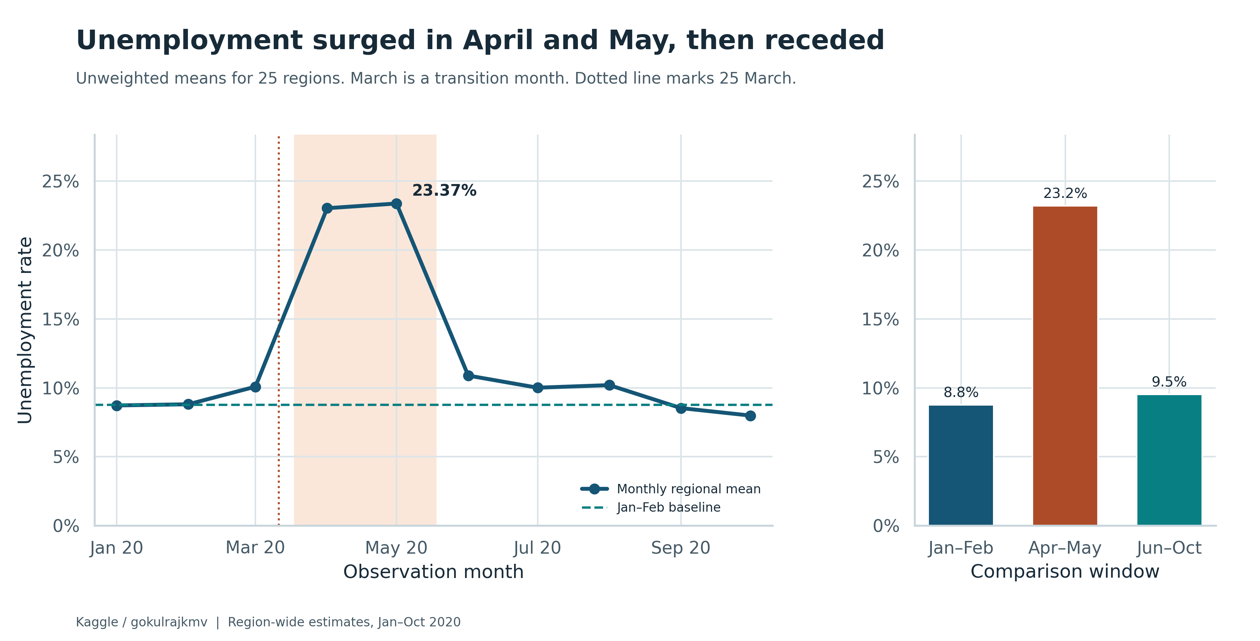

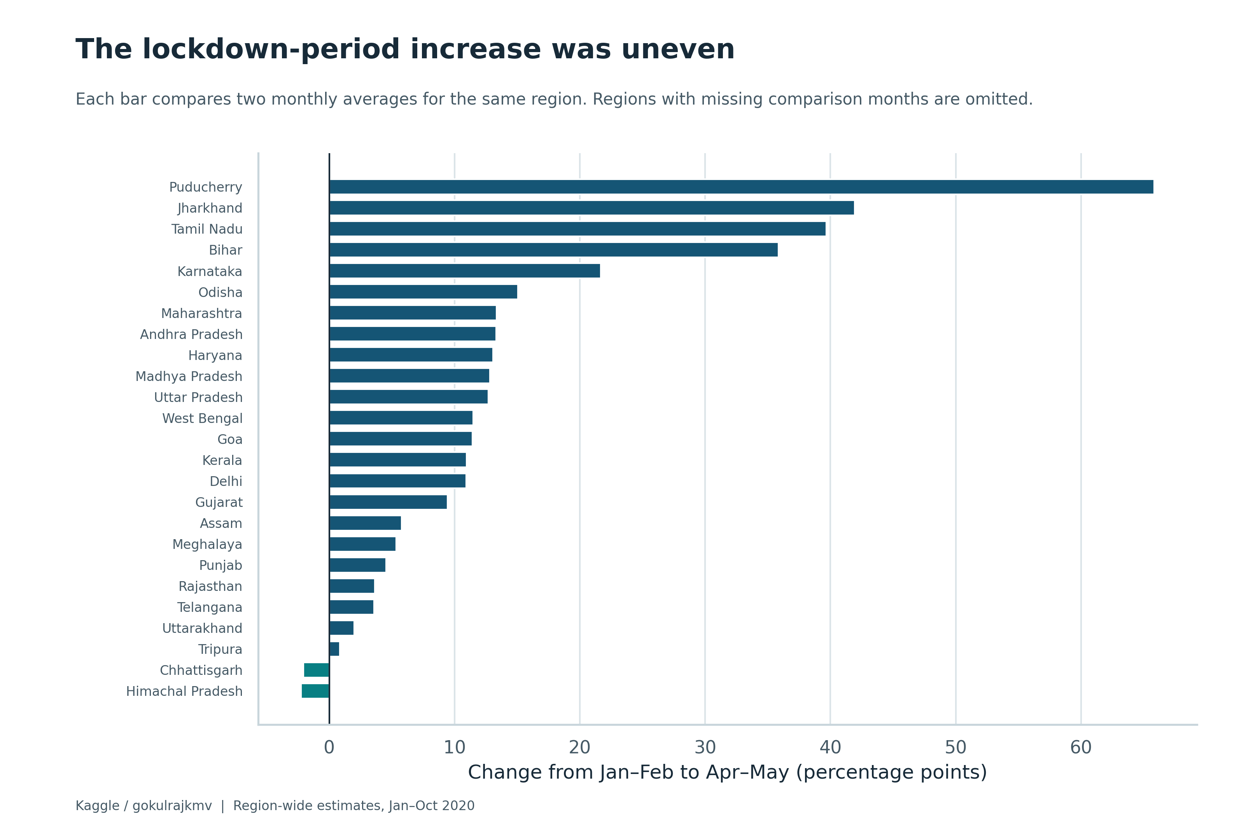

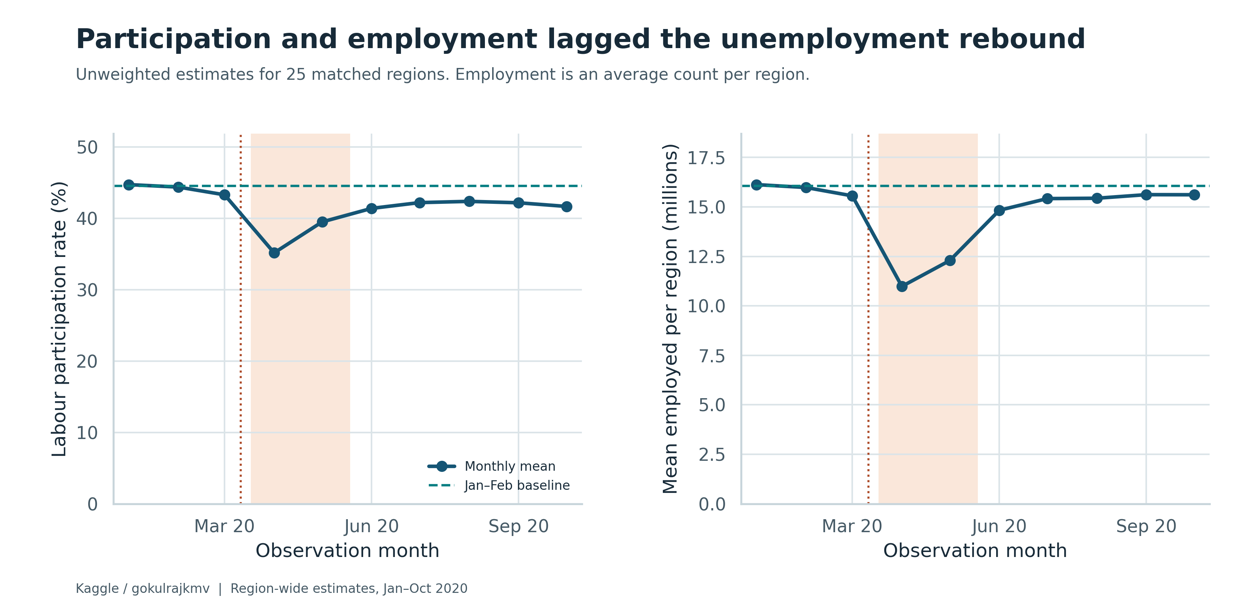

In [10]:
display(tables["covid_periods"][[*fields, "unemployment_relative_pct"]])
for key in ["shock", "recovery", "labour"]:
    display(Markdown(summary[key]))
show("03_lockdown_and_reopening")
show("05_regional_shock")
show("10_participation_employment")

### 14 · Statistical analysis
Resample paired region-level changes 20,000 times and use an exact two-sided sign test to check the direction of changes. The p-values and intervals are exploratory because a common national shock may correlate regions. Shapiro–Wilk describes departures from normality, and leave-one-region-out means check sensitivity to individual regions. Pearson and Spearman correlations are descriptive. Demeaning removes regional level differences while leaving shared monthly movements.

,contrast,regions,mean_pp,median_pp,sd_pp,paired_cohens_dz,bootstrap_95_low_pp,bootstrap_95_high_pp,bootstrap_draws,positive,negative,ties,exact_sign_p,shapiro_p,leave_one_out_min_pp,leave_one_out_max_pp
0,Regional shock minus baseline,25,14.441,11.430,15.816,0.913,8.922,21.090,20000,23,2,0,1.94e-05,0.000152,12.299,15.137
1,Urban minus rural shock change,20,1.411,4.060,8.798,0.160,-2.422,5.135,20000,12,8,0,0.503,0.581,0.549,2.227


Unemployment rose in 23 of 25 regions (median change +11.43 pp). The bootstrap 95% interval for the mean change was 8.92 to 21.09 pp. The two-sided sign test gave p = 1.9e-05; paired Cohen's dz was 0.91. Shapiro-Wilk p = 0.00015 suggests asymmetric or non-normal differences. Leaving out one region at a time put the mean change between 12.30 and 15.14 pp.

The pooled Pearson correlations of unemployment with estimated employment and participation were -0.25 and -0.07. After removing each region's average, they were -0.58 and -0.06. The within-region associations can still reflect common shocks and linked labour-market definitions.

,panel,unemployment_change_pp
2,Jan-May complete,14.44
6,Jan-Oct complete,14.44


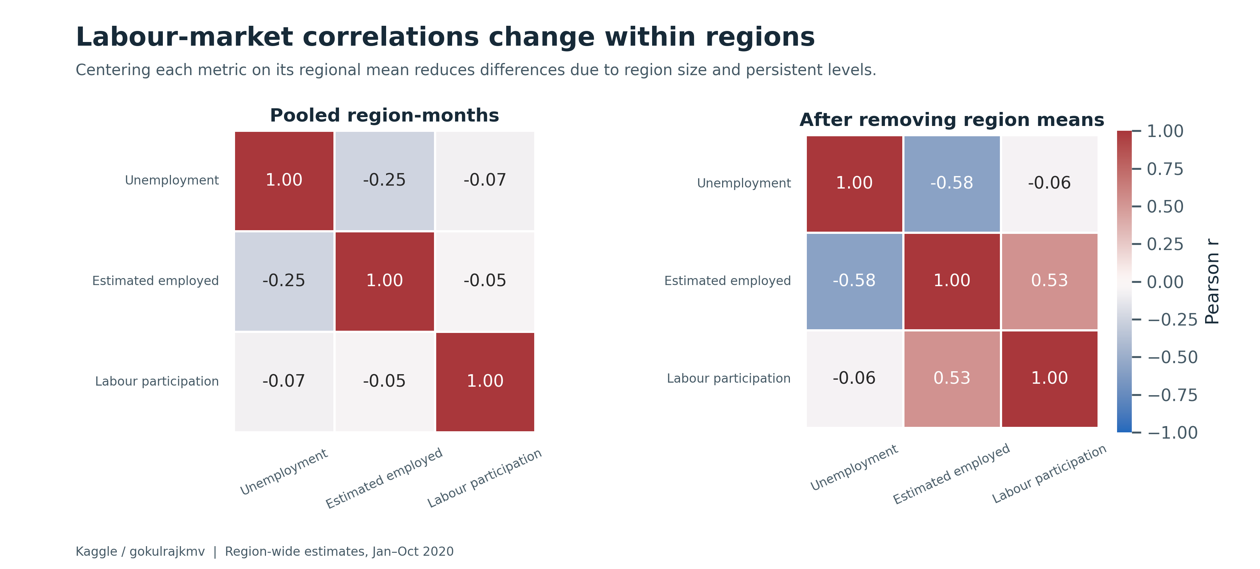

In [11]:
display(tables["paired_inference"].style.format(precision=3).format(
    "{:.3g}", subset=["exact_sign_p", "shapiro_p"]))
for key in ["inference", "correlation"]:
    display(Markdown(summary[key]))
display(tables["covid_sensitivity"].query("period == 'Shock'")[["panel", "unemployment_change_pp"]])
show("09_correlations")

### 15 · Monthly and seasonal analysis
Compare calendar months across years only where both years are observed. Calendar averages for most months use a single observation, and partial-year means cover different months.

,calendar_month,mean,observed_years
0,1,10.47,1
1,2,10.73,1
2,3,11.26,1
3,4,24.25,1
4,5,18.18,2
5,6,11.62,2
6,7,9.48,1
7,8,10.71,1
8,9,10.13,1
9,10,10.35,1


,year,mean,observed_months
0,2019,10.07,8
1,2020,16.18,6


year,calendar_month,2019,2020,change_pp
0,5,9.39,26.98,17.60
1,6,9.86,13.39,3.53


Only May and June repeat across the 14-month area series. The matched year-over-year differences were +17.60 pp in May and +3.53 pp in June. The largest month-to-month increase was +13.00 pp in April 2020. With fewer than two annual cycles and pandemic disruption in one of the years, these comparisons are exploratory. STL and forecasting were omitted.

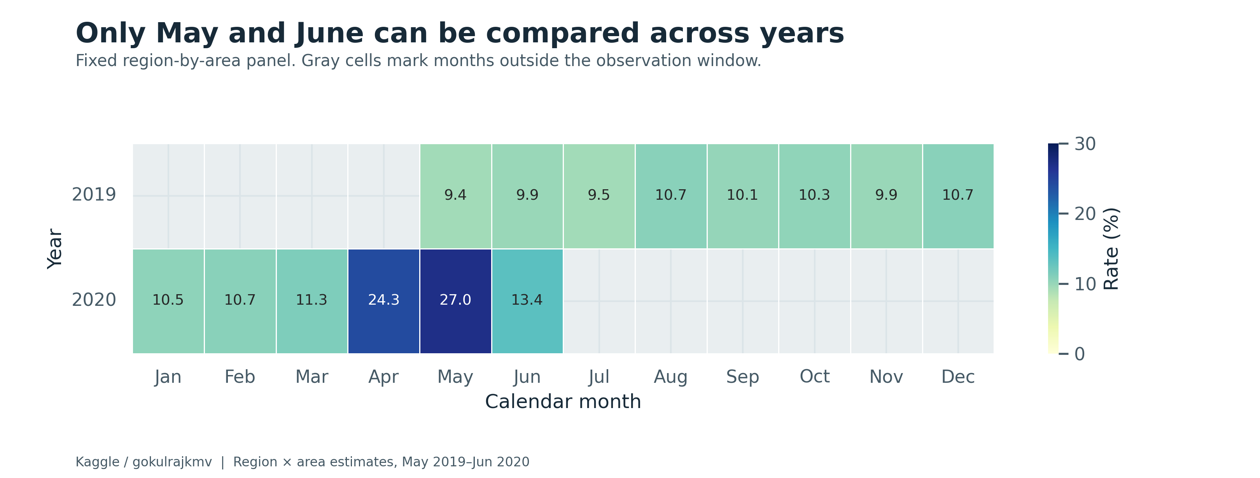

In [12]:
display(tables["calendar_months"])
display(tables["historical_years"])
display(tables["same_month_year_comparison"])
display(Markdown(summary["seasonality"]))
show("07_calendar_heatmap")

### 16 · Data visualization
The paired histogram and boxplot show why the median and IQR complement the mean and standard deviation. The other figures are embedded alongside their analytical sections. All ten figures also export as 300-DPI PNGs.

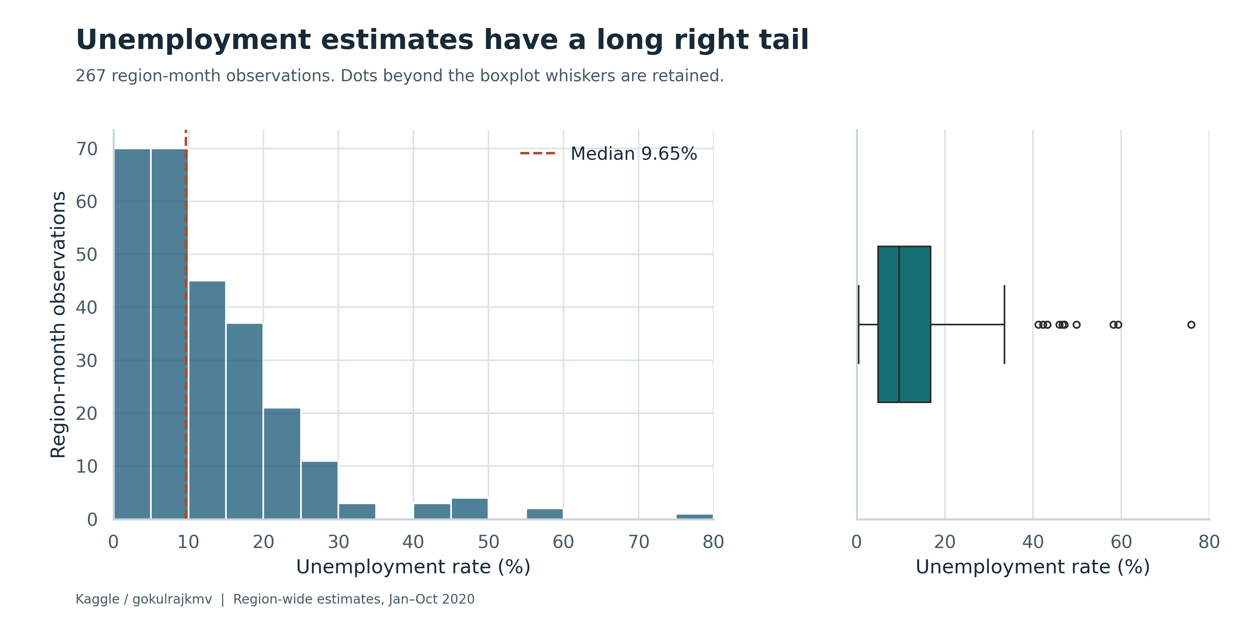

In [13]:
show("01_distribution")

### 17 · Policy recommendations
Treat these proposals as interventions to pilot and evaluate using local evidence and worker-level follow-up.

In [14]:
for key in ["policy_region", "policy_area", "policy_monitoring"]:
    display(Markdown(f"- {summary[key]}"))

- Pilot rapid-response placement and payroll support where unemployment increased most, beginning with Puducherry and other severely affected regions. Validate local indicators and employer demand before allocating support, then track re-employment and retention.

- Test job-matching and temporary income support for urban workers alongside rural public works for households facing a sudden loss of work. Both area means rose sharply, and the evidence leaves the urban-rural difference uncertain. Track access and outcomes separately by area.

- Include participation and employment alongside unemployment in recovery dashboards. October unemployment had fallen below baseline while the other two measures remained lower. Use survey weights and worker-level follow-up to identify groups that stopped looking for work.

### 18 · Limitations
The release lacks survey weights, sampling uncertainty and worker characteristics. Equal-weight regional means describe the included regions and differ in scope from official national rates. Complete-case panels exclude regions with missing months. The short baseline and shared disruption leave no credible counterfactual. The area series ends in June and the regional series in October 2020, so the evidence supports a short-run assessment.

### 19 · Final conclusion
The first full lockdown months coincide with a broad unemployment surge. By October the regional unemployment mean had returned close to baseline, while participation and estimated employment remained lower. Local differences and a short observation window make continued measurement important.